# Phase 2 — Exploratory Data Analysis: FD004
**Notebook:** `11_EDA_FD004.ipynb` · **Project:** Intelligent Predictive Maintenance — RUL Estimation

FD004 = 249 training engines, 248 test engines, **6 operating conditions, 2 fault modes** (HPC + fan degradation): the hardest subset.

**What's new compared with FD001/FD002: two fault modes.** Some engines fail through high-pressure-compressor (HPC) wear, others through fan wear. Several sensors move **in opposite directions** depending on the fault, so section 2.11 checks this directly.
It also has FD002's six operating regimes, so the regime analysis and per-regime normalisation from `05_EDA_FD002` are repeated here.

EDA only reads and plots. Every decision is proposed here and made in Phase 3 (`12_Preprocessing_FD004`). The **Key findings** section at the end lists the actual numbers from a full local run.

⚙️ CPU is fine, about 1–3 minutes.

## Cell 1 — Setup

In [1]:
# Cell 1 — Setup
import os, sys, json, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:
    RAW_DIR     = Path(os.environ["CMAPSS_RAW_DIR"])
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])

FD, SEED = "FD004", 42
FIG_DIR = PROJECT_DIR / "reports" / "figures" / FD
TAB_DIR = PROJECT_DIR / "reports" / "eda" / FD
for p in (FIG_DIR, TAB_DIR):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
save_fig = lambda fig, name: fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

import src.data_loader as dl, src.preprocessing as pp
importlib.reload(dl); importlib.reload(pp)
SETTINGS, SENSORS = dl.SETTING_COLS, dl.SENSOR_COLS
print("Ready")

Ready


## Cell 2 — Load (read-only) and add an EDA-only RUL column

In [2]:
# Cell 2 — Load
d = dl.load_dataset(FD, RAW_DIR)
train, test, rul = d["train"], d["test"], d["rul"]
eda = train.copy()
eda["RUL"] = eda.groupby("engine_id")["cycle"].transform("max") - eda["cycle"]
print(f"train {train.shape} | {train.engine_id.nunique()} engines")
print(f"test  {test.shape} | {test.engine_id.nunique()} engines | RUL file {len(rul)} rows")
print("Missing values:", int(train.isna().sum().sum()), "/", int(test.isna().sum().sum()))

train (61249, 26) | 249 engines
test  (41214, 26) | 248 engines | RUL file 248 rows
Missing values: 0 / 0


---
## 2.1 — Engine lifetime distribution

Train lifetimes: {'count': 249.0, 'mean': 246.0, 'std': 73.1, 'min': 128.0, '25%': 190.0, '50%': 234.0, '75%': 290.0, 'max': 543.0} | skew 0.91
Test observed lengths: {'count': 248.0, 'mean': 166.2, 'std': 91.6, 'min': 19.0, '25%': 102.0, '50%': 153.5, '75%': 218.5, 'max': 486.0}
Test engines with fewer than 21 cycles: 4
Test engines with fewer than 30 cycles: 11
Test engines with fewer than 40 cycles: 16


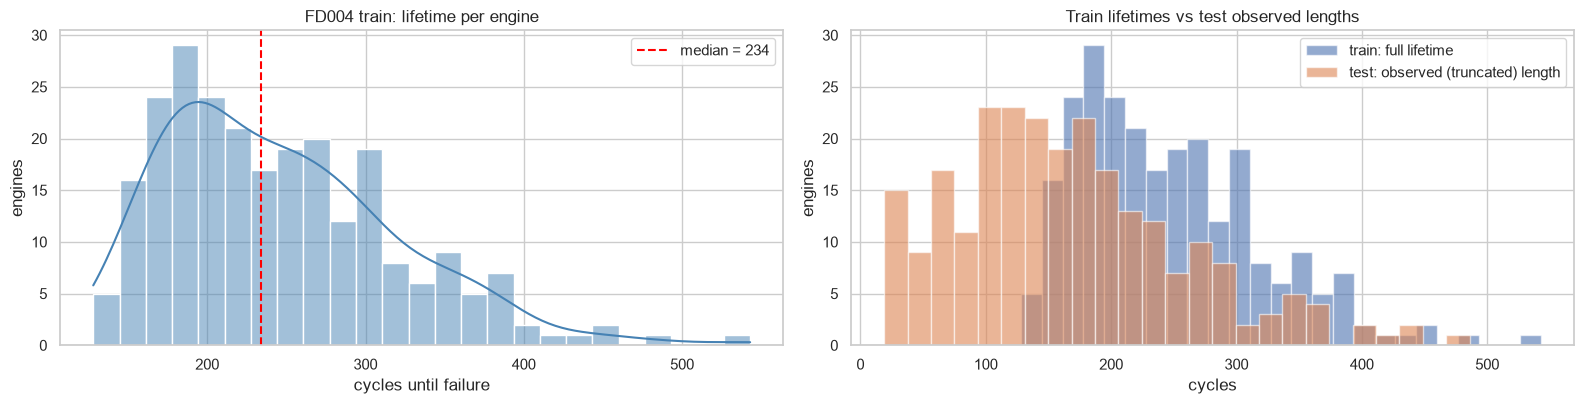

In [3]:
# Cell 3 — Lifetimes vs test observed lengths
train_life = train.groupby("engine_id")["cycle"].max()
test_obs = test.groupby("engine_id")["cycle"].max()
print("Train lifetimes:", train_life.describe().round(1).to_dict(), "| skew", round(train_life.skew(), 2))
print("Test observed lengths:", test_obs.describe().round(1).to_dict())
for k in (21, 30, 40):
    print(f"Test engines with fewer than {k} cycles: {(test_obs < k).sum()}")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
sns.histplot(train_life, bins=25, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(train_life.median(), color="red", ls="--", label=f"median = {train_life.median():.0f}")
axes[0].set(title=f"{FD} train: lifetime per engine", xlabel="cycles until failure", ylabel="engines"); axes[0].legend()
axes[1].hist(train_life, bins=25, alpha=0.6, label="train: full lifetime")
axes[1].hist(test_obs, bins=25, alpha=0.6, label="test: observed (truncated) length")
axes[1].set(title="Train lifetimes vs test observed lengths", xlabel="cycles", ylabel="engines"); axes[1].legend()
fig.tight_layout(); save_fig(fig, "01_engine_lifetime_distribution"); plt.show()

**How to read it:** the left plot shows how long engines live. The right plot compares that with how much history each **test** engine gives us. The shortest test history sets the **longest LSTM window** we can use without padding, and the minimum history for the test-like validation points in Phase 3.

## 2.2 — Operating cycle coverage

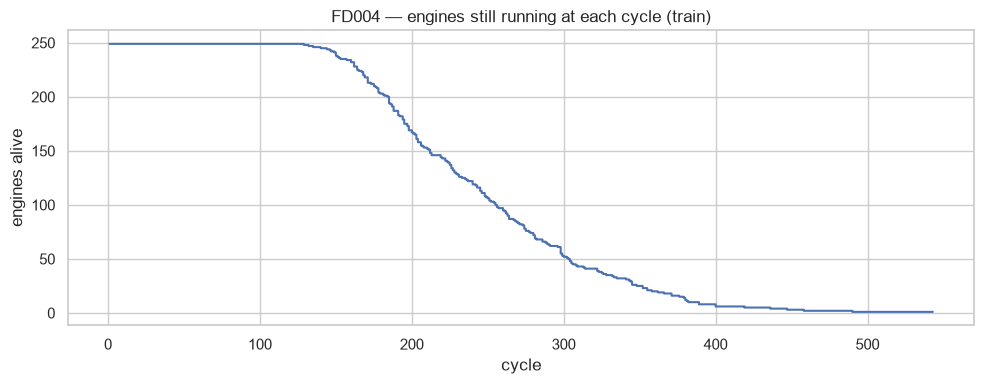

Engines alive at cycle 150 / 200 / 300 / 400: [238, 167, 52, 6]


In [4]:
# Cell 4 — Engines still running at each cycle
alive = pd.Series([(train_life >= t).sum() for t in range(1, train_life.max() + 1)], index=range(1, train_life.max() + 1))
fig, ax = plt.subplots(figsize=(10, 4))
ax.step(alive.index, alive.values, where="post")
ax.set(title=f"{FD} — engines still running at each cycle (train)", xlabel="cycle", ylabel="engines alive")
fig.tight_layout(); save_fig(fig, "02_cycle_coverage"); plt.show()
print("Engines alive at cycle 150 / 200 / 300 / 400:", [int(alive.get(c, 0)) for c in (150, 200, 300, 400)])

---
## 2.3 — Operating settings & regime discovery

,regime,op_setting_1,op_setting_2,op_setting_3,train_rows,share
0,1,0.0,0.00,100.0,9238,0.151
1,2,10.0,0.25,100.0,9224,0.151
2,3,20.0,0.70,100.0,9091,0.148
3,4,25.0,0.62,60.0,9139,0.149
4,5,35.0,0.84,100.0,9162,0.150
5,6,42.0,0.84,100.0,15395,0.251


Test rows in an unknown regime: 0


K-Means agrees with rounding: True
Share of cycles where the regime changes: 82.1%


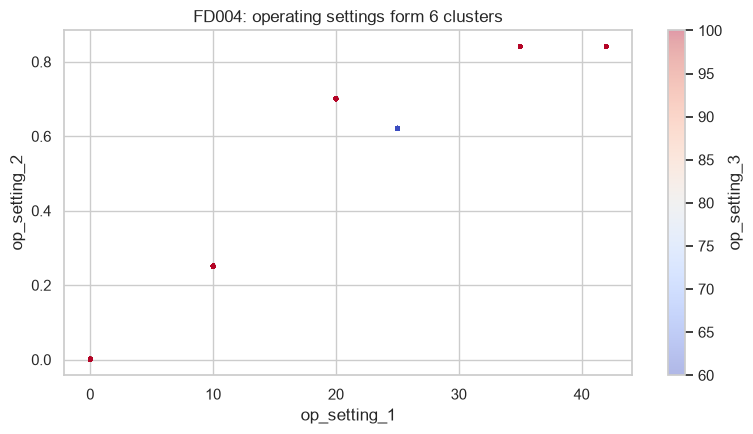

In [5]:
# Cell 5 — Regimes (same rounding rule as FD002, cross-checked with K-Means)
ROUND = {"op_setting_1": 0, "op_setting_2": 2, "op_setting_3": 0}
regime_table = train[SETTINGS].round(ROUND).drop_duplicates().sort_values(SETTINGS).reset_index(drop=True)
regime_table.insert(0, "regime", np.arange(1, len(regime_table) + 1))
lookup = {tuple(r[SETTINGS]): int(r.regime) for _, r in regime_table.iterrows()}
assign = lambda df: pd.Series([lookup.get(k, -1) for k in map(tuple, df[SETTINGS].round(ROUND).values)], index=df.index)
eda["regime"] = assign(eda); test_regime = assign(test)
regime_table["train_rows"] = eda.regime.value_counts().reindex(regime_table.regime).values
regime_table["share"] = (regime_table.train_rows / len(eda)).round(3)
display(regime_table)
print("Test rows in an unknown regime:", int((test_regime == -1).sum()))
from sklearn.cluster import KMeans
km = KMeans(n_clusters=len(regime_table), n_init=10, random_state=SEED).fit(train[SETTINGS])
print("K-Means agrees with rounding:", bool(((pd.crosstab(km.labels_, eda.regime) > 0).sum(axis=1) == 1).all()))
switch_rate = eda.groupby("engine_id").regime.apply(lambda s: (s.diff().fillna(0) != 0).mean()).mean()
print(f"Share of cycles where the regime changes: {switch_rate:.1%}")
N_REGIMES = len(regime_table)
fig, ax = plt.subplots(figsize=(8, 4.5))
sc = ax.scatter(train.op_setting_1, train.op_setting_2, c=train.op_setting_3, cmap="coolwarm", s=4, alpha=0.4)
fig.colorbar(sc, ax=ax, label="op_setting_3")
ax.set(title=f"{FD}: operating settings form {N_REGIMES} clusters", xlabel="op_setting_1", ylabel="op_setting_2")
fig.tight_layout(); save_fig(fig, "03_operating_regimes"); plt.show()

**How to read it:** if the settings form a few tight clusters (and K-Means agrees), each cluster is one flight condition. As in FD002, the condition is re-drawn almost every cycle, so it carries no wear information. It only shifts every sensor's normal level.

## 2.4 — Sensor statistical summary (raw)

In [6]:
# Cell 6 — Raw descriptive statistics
summary = train[SENSORS].describe().T
summary["n_unique"] = train[SENSORS].nunique()
summary.to_csv(TAB_DIR / "feature_summary_raw.csv")
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,n_unique
sensor_1,61249.0,472.882,26.437,445.000,445.000,462.540,491.190,518.670,6
sensor_2,61249.0,579.420,37.343,535.480,549.330,555.740,607.070,644.420,1704
sensor_3,61249.0,1417.897,106.168,1242.670,1350.550,1367.680,1497.420,1613.000,13558
sensor_4,61249.0,1201.915,119.328,1024.420,1119.490,1136.920,1302.620,1440.770,17353
sensor_5,61249.0,8.032,3.623,3.910,3.910,7.050,10.520,14.620,6
sensor_6,61249.0,11.589,5.444,5.670,5.720,9.030,15.480,21.610,46
sensor_7,61249.0,283.329,146.880,136.170,142.920,194.960,394.280,570.810,5926
sensor_8,61249.0,2228.686,145.348,1914.720,2211.950,2223.070,2323.930,2388.640,1038
sensor_9,61249.0,8524.673,336.928,7984.510,8320.590,8362.760,8777.250,9196.810,25297
sensor_10,61249.0,1.096,0.128,0.930,1.020,1.030,1.260,1.320,21


## 2.5 — Sensor distributions

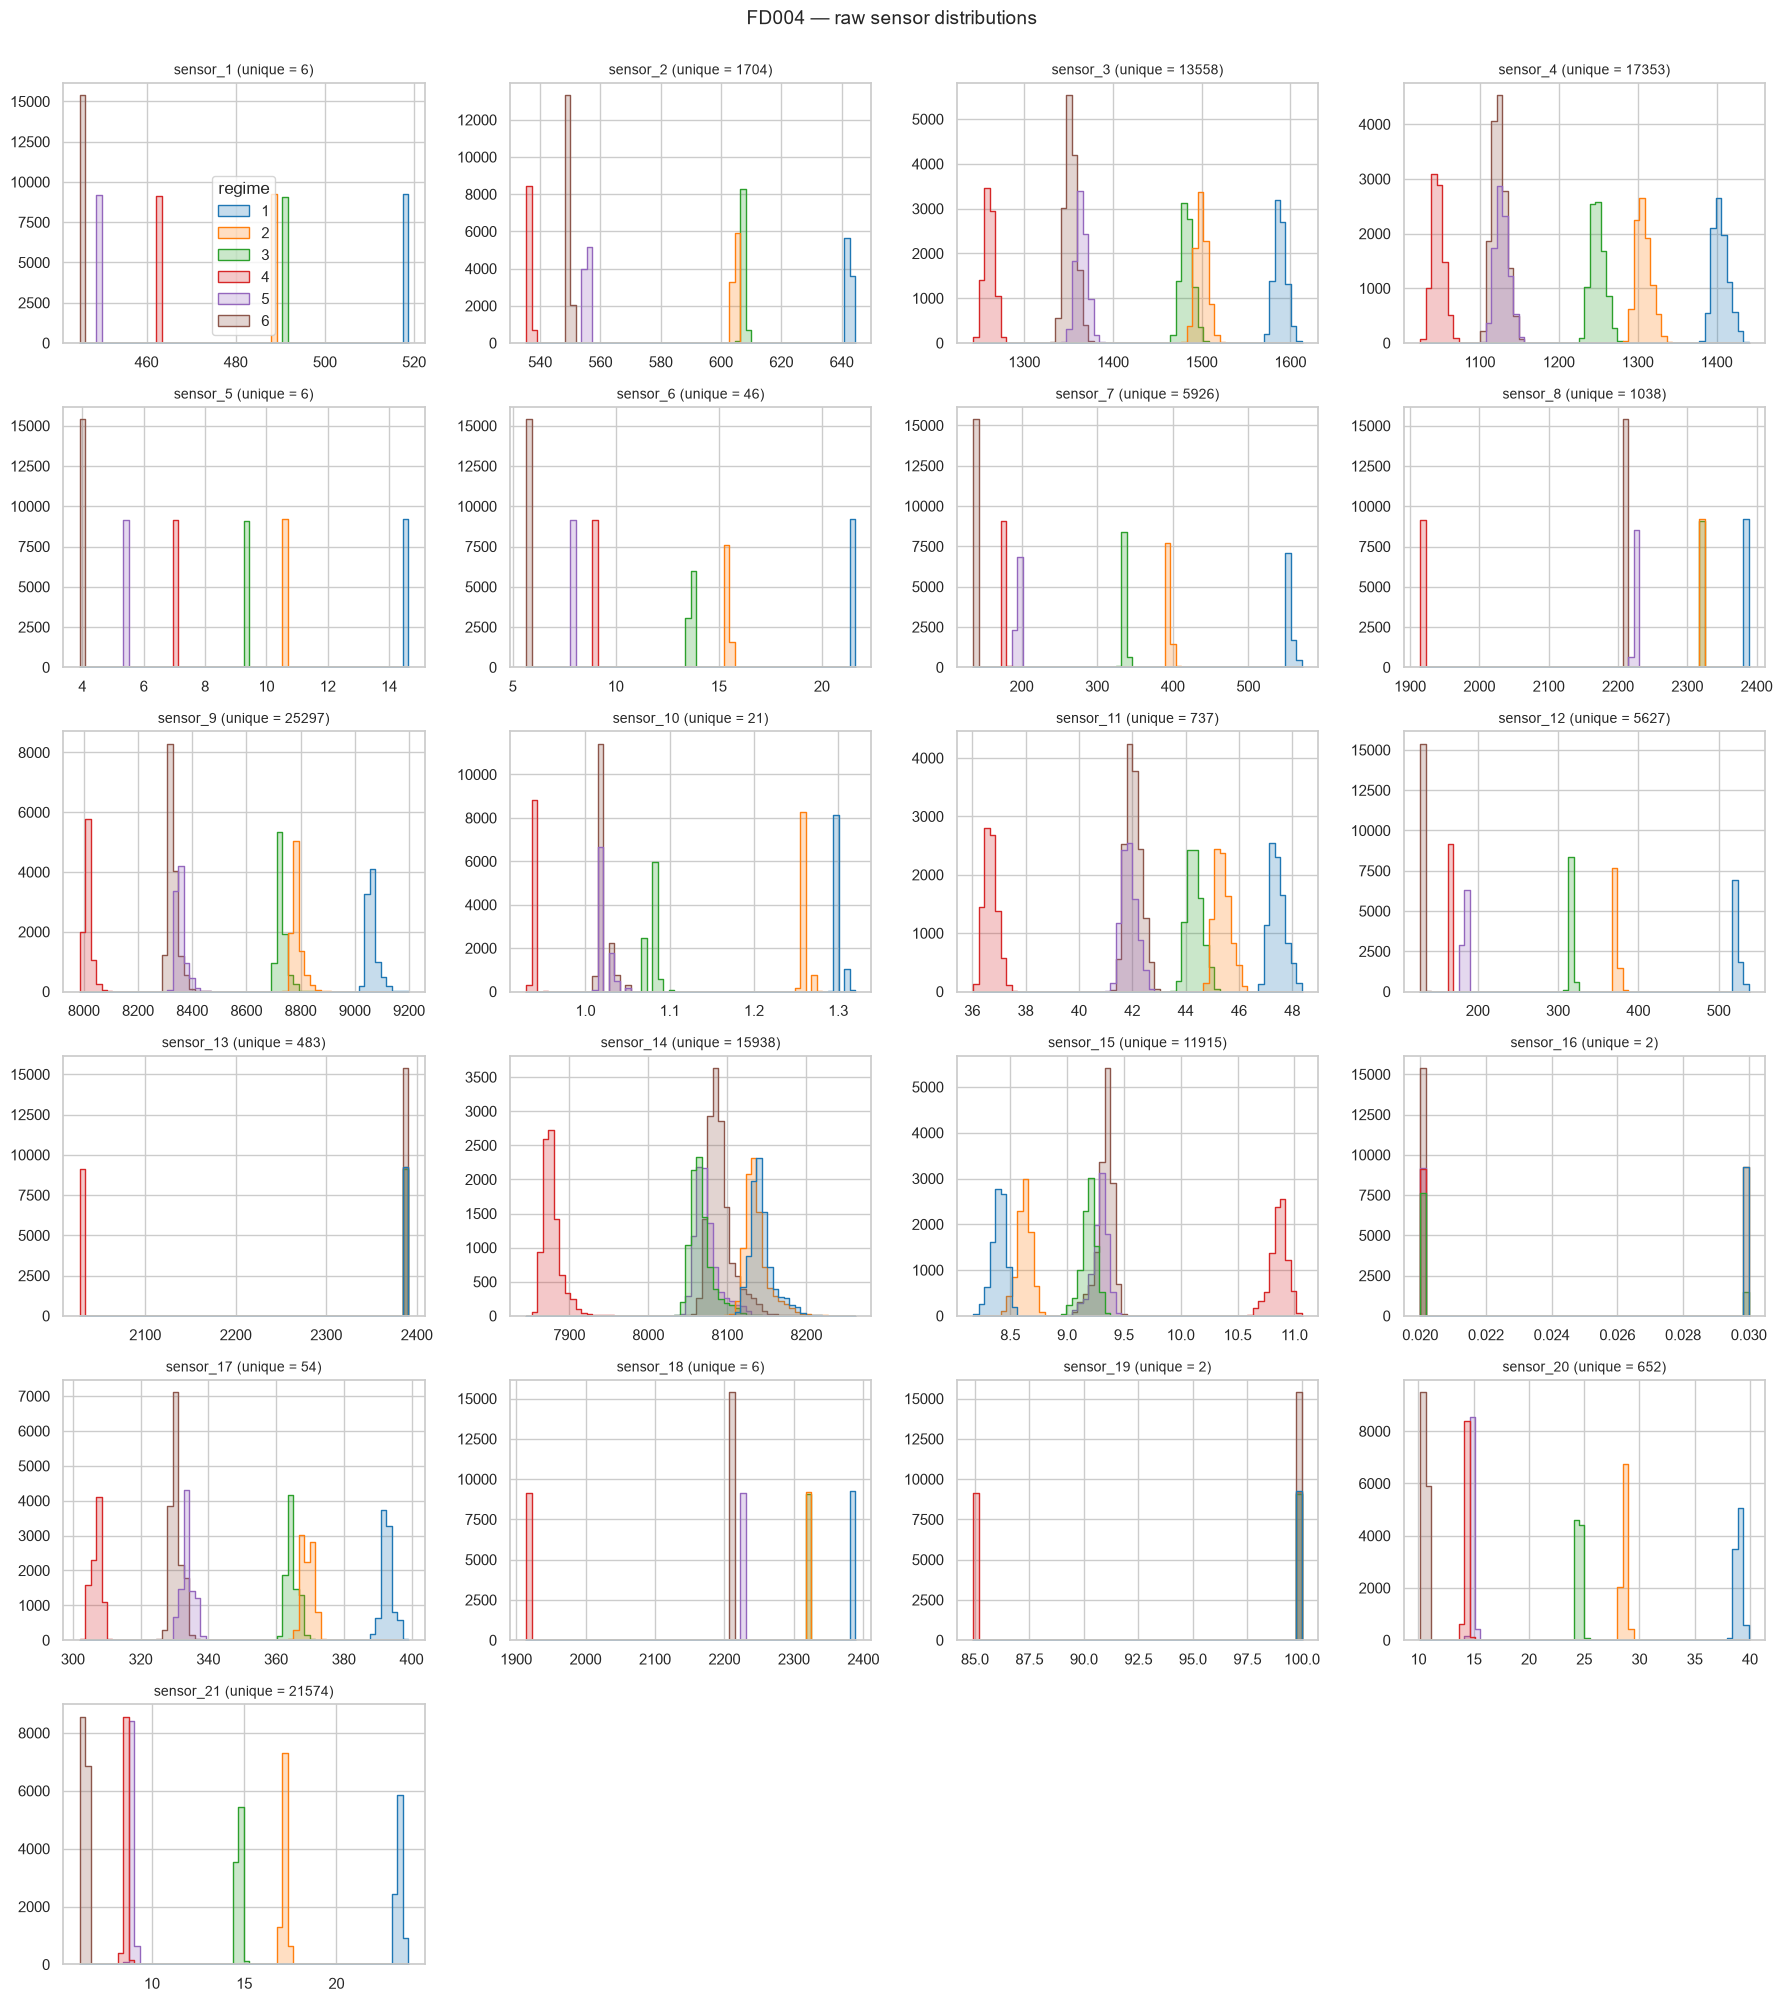

In [7]:
# Cell 7 — Histograms (coloured by regime)
fig, axes = plt.subplots(6, 4, figsize=(18, 20))
for i, (ax, col) in enumerate(zip(axes.flat, SENSORS)):
    sns.histplot(eda, x=col, hue="regime", bins=60, element="step", palette="tab10", ax=ax, legend=(i == 0))
    ax.set_title(f"{col} (unique = {train[col].nunique()})", fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[len(SENSORS):]:
    ax.axis("off")
fig.suptitle(f"{FD} — raw sensor distributions", y=1.0, fontsize=14)
fig.tight_layout(); save_fig(fig, "04_sensor_distributions"); plt.show()

## 2.6 — Variance analysis: which sensors carry information?

In [8]:
# Cell 8 — Within-regime variability (the right test when there are several regimes)
g = eda.groupby("regime")[SENSORS]
var_df = pd.DataFrame({"raw_n_unique": train[SENSORS].nunique(),
                       "max_n_unique_within_regime": g.nunique().max(),
                       "variance_explained_by_regime_%": (1 - g.var().mean() / train[SENSORS].var().replace(0, np.nan)) * 100})
n_ref = var_df.max_n_unique_within_regime

In [9]:
var_df["flag"] = np.select([n_ref == 1, n_ref < 3], ["CONSTANT", "QUANTISED (<3 values)"], default="variable")
var_df.to_csv(TAB_DIR / "variance_report.csv")
display(var_df.round(3))
CONSTANT = var_df.index[var_df.flag == "CONSTANT"].tolist()
QUANT = var_df.index[var_df.flag.str.startswith("QUANTISED")].tolist()
VARIABLE = var_df.index[var_df.flag == "variable"].tolist()
print("CONSTANT:", CONSTANT); print("QUANTISED:", QUANT); print("variable:", VARIABLE)

,raw_n_unique,max_n_unique_within_regime,variance_explained_by_regime_%,flag
sensor_1,6,1,100.000,CONSTANT
sensor_2,1704,308,99.983,variable
sensor_3,13558,3032,99.629,variable
sensor_4,17353,3844,99.445,variable
sensor_5,6,1,100.000,CONSTANT
sensor_6,46,12,99.999,variable
sensor_7,5926,1533,99.980,variable
sensor_8,1038,237,100.000,variable
sensor_9,25297,5765,99.724,variable
sensor_10,21,6,99.844,variable


CONSTANT: ['sensor_1', 'sensor_5', 'sensor_18', 'sensor_19']
QUANTISED: ['sensor_16']
variable: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 2.7 — Normalisation for comparison
Per-regime z-scores, as in FD002 (EDA only, using all training engines; Phase 3 fits on the training split only).

In [10]:
# Cell 9 — z-scores for EDA
gstats = eda.groupby("regime")[SENSORS]
mu, sd = gstats.transform("mean"), gstats.transform("std").replace(0, np.nan)
z = eda[["engine_id", "cycle", "RUL"]].join((eda[SENSORS] - mu) / sd)
CHECK = [c for c in VARIABLE + QUANT if z[c].notna().any()]
print("Sensors analysed below:", CHECK)

Sensors analysed below: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'sensor_16']


## 2.8 — Correlation with RUL

,raw,normalised
sensor_11,-0.057,-0.688
sensor_4,-0.046,-0.653
sensor_17,-0.033,-0.607
sensor_3,-0.033,-0.584
sensor_2,-0.004,-0.531
sensor_9,-0.025,-0.524
sensor_13,0.002,-0.487
sensor_8,0.002,-0.486
sensor_14,-0.078,-0.450
sensor_10,-0.009,-0.316


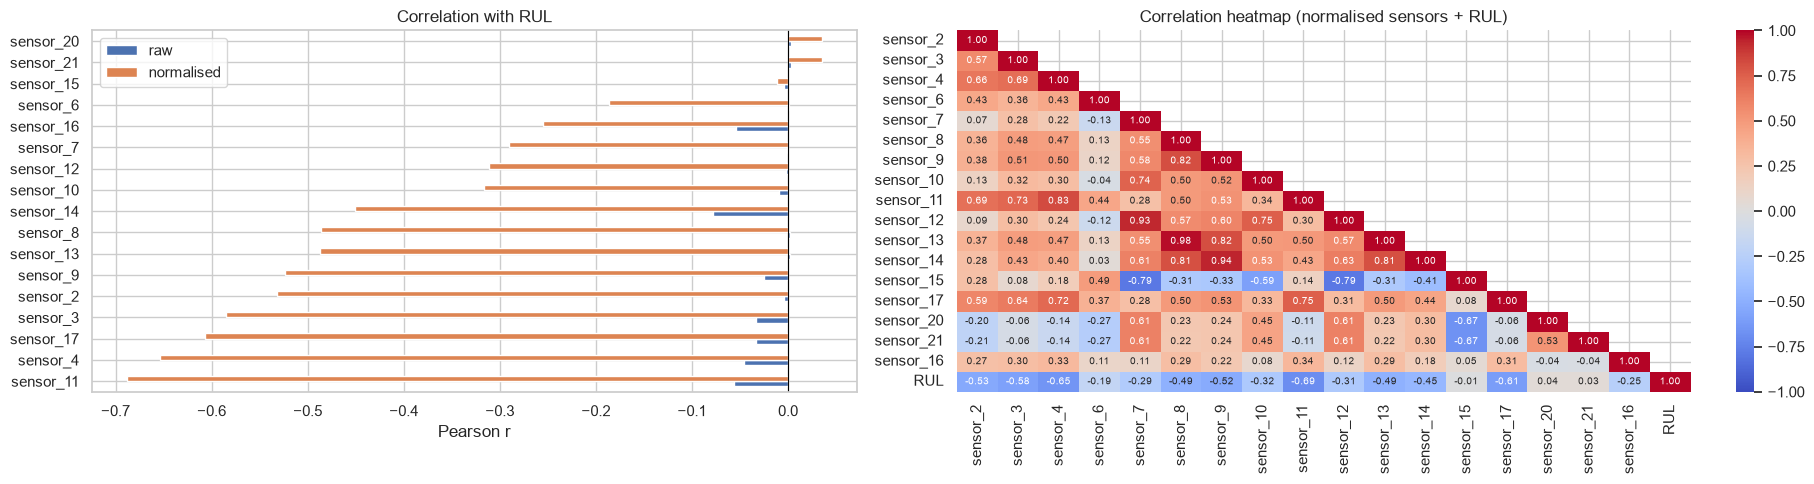

In [11]:
# Cell 10 — Correlation with RUL (raw vs regime-normalised)
corr = pd.DataFrame({"raw": eda[CHECK + ["RUL"]].corr()["RUL"].drop("RUL"), "normalised": z[CHECK + ["RUL"]].corr()["RUL"].drop("RUL")}).sort_values("normalised")
corr.to_csv(TAB_DIR / "correlation_with_rul.csv")
display(corr.round(3))
fig, axes = plt.subplots(1, 2, figsize=(19, 5), gridspec_kw={"width_ratios": [1, 1.2]})
corr.plot.barh(ax=axes[0]); axes[0].axvline(0, color="black", lw=0.8)
axes[0].set(title="Correlation with RUL", xlabel="Pearson r")
hm = z[CHECK + ["RUL"]].corr()
sns.heatmap(hm, mask=np.triu(np.ones_like(hm, bool), k=1), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Correlation heatmap (normalised sensors + RUL)")
fig.tight_layout(); save_fig(fig, "05_correlation"); plt.show()

**How to read it:** strongly negative = the sensor rises as the engine wears out; positive = it falls.

**Watch out in this dataset:** a correlation **near 0** does not automatically mean "useless". With two fault modes, a sensor that rises for one fault and falls for the other averages out to about 0 over all engines. Section 2.11 checks this directly.

## 2.9 — Sensor trends across cycles (10 random engines)

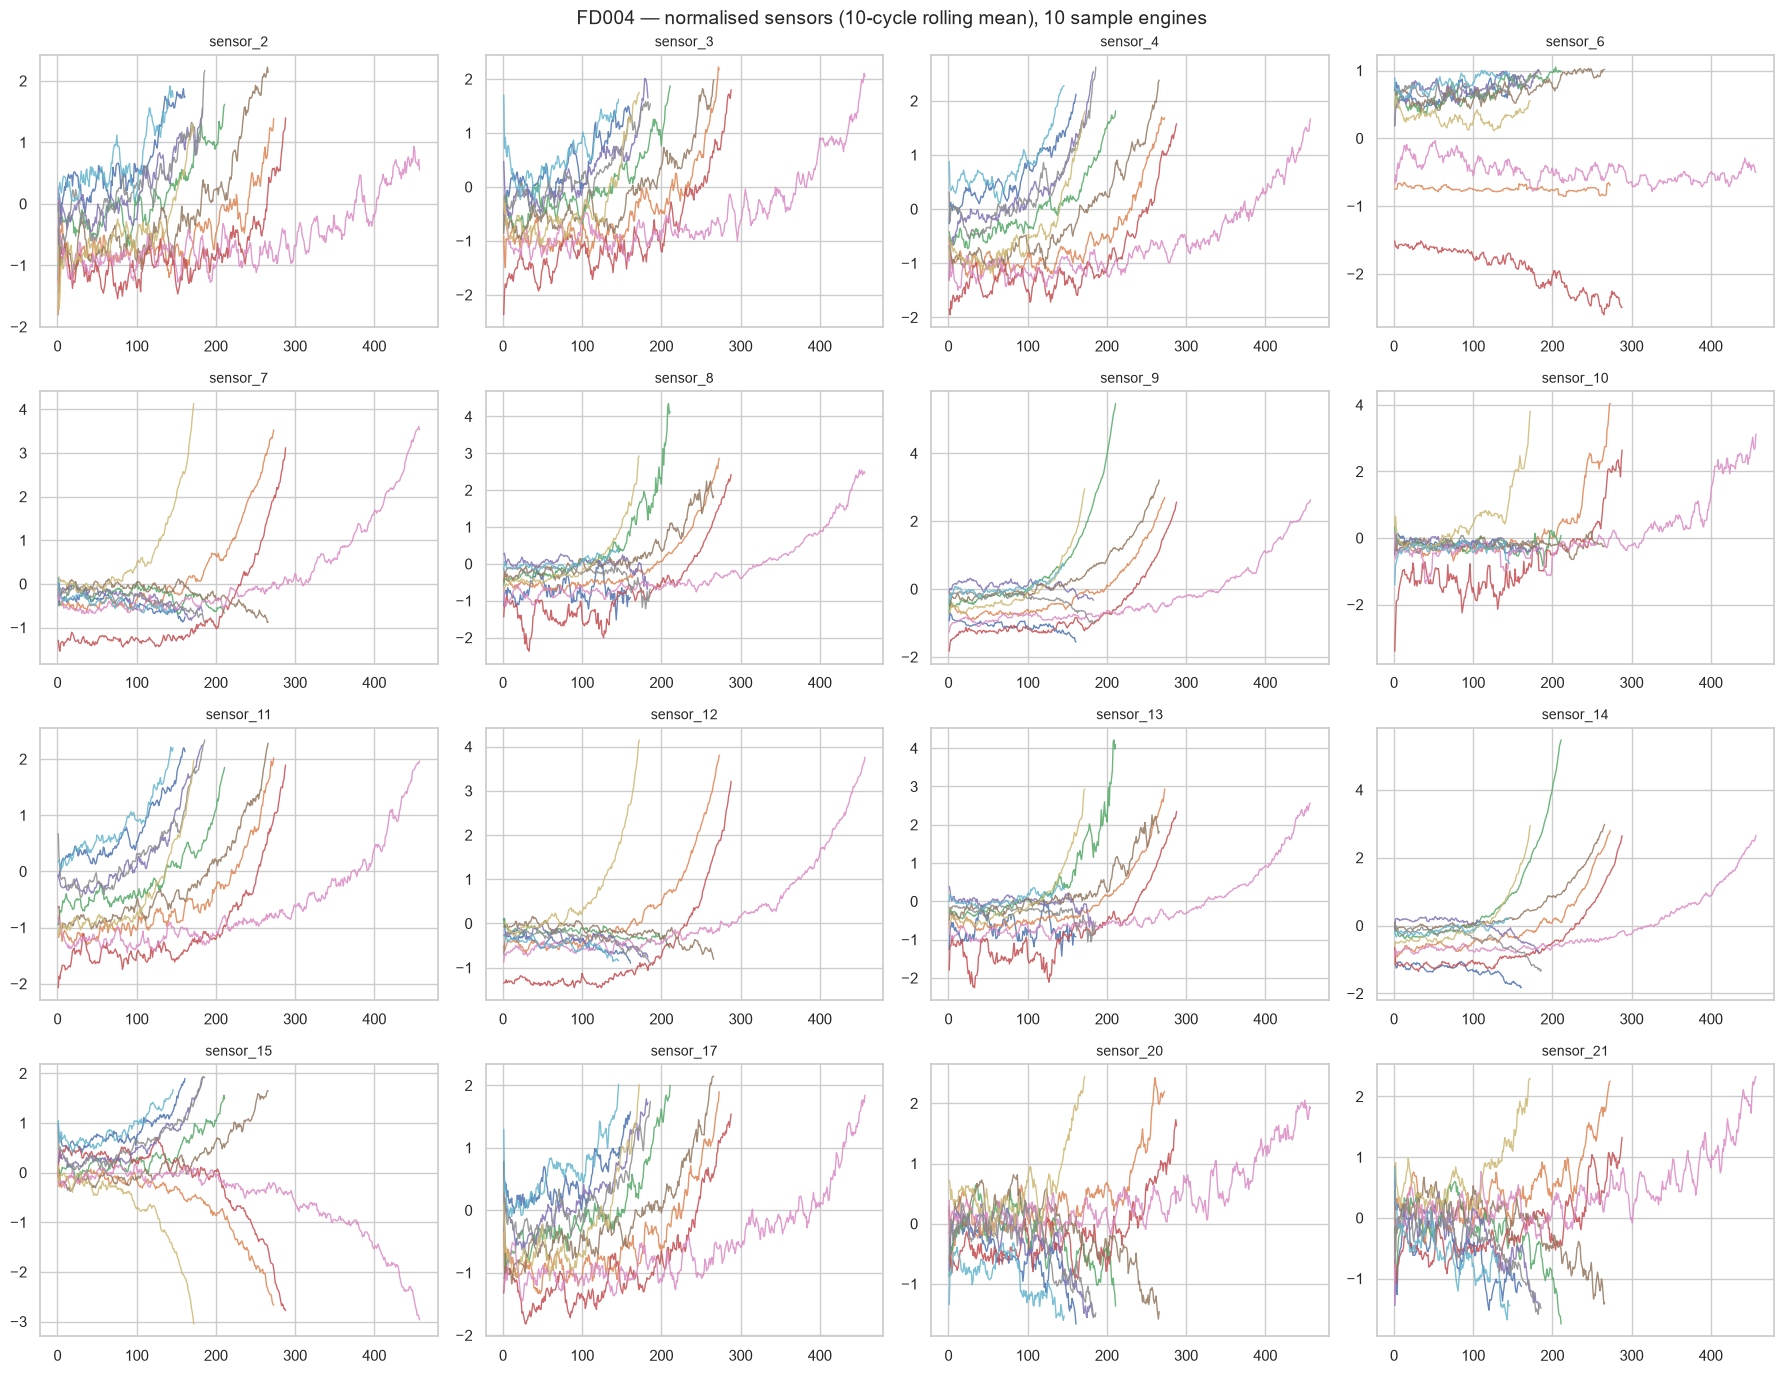

In [12]:
# Cell 11 — 10-cycle rolling mean of normalised sensors
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(eda.engine_id.unique(), size=10, replace=False)
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, CHECK[:16]):
    for e in sample_ids:
        g_ = z[z.engine_id == e]
        ax.plot(g_.cycle, g_[col].rolling(10, min_periods=1).mean(), lw=1, alpha=0.85)
    ax.set_title(col, fontsize=10)
for ax in axes.flat[len(CHECK[:16]):]:
    ax.axis("off")
fig.suptitle(f"{FD} — normalised sensors (10-cycle rolling mean), 10 sample engines", fontsize=14)
fig.tight_layout(); save_fig(fig, "06_sensor_trends_sample_engines"); plt.show()

## 2.10 — Degradation aligned at failure

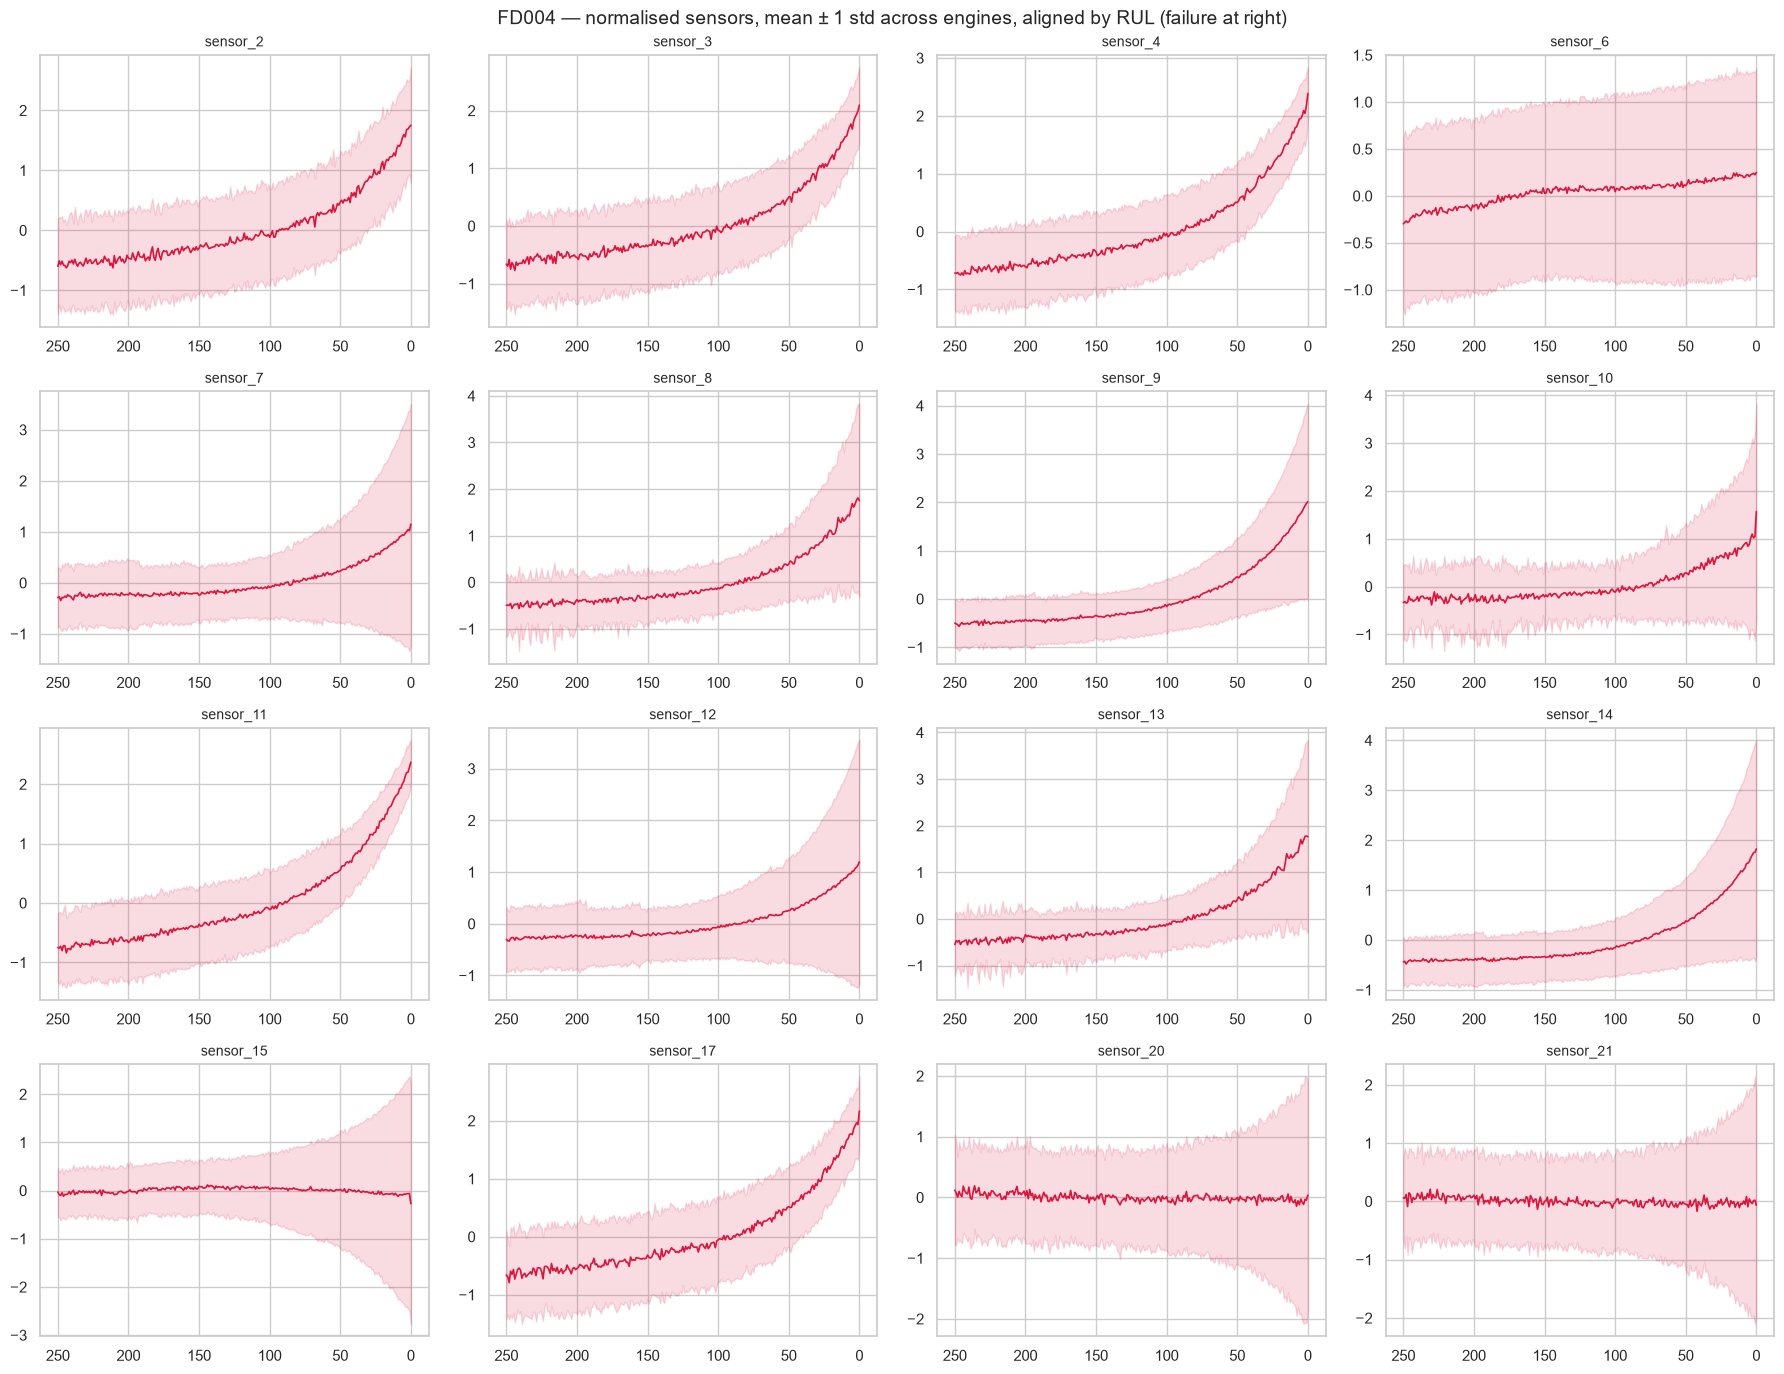

,shift_in_early_std
sensor_15,-0.42
sensor_20,-0.02
sensor_21,-0.01
sensor_6,0.10
sensor_16,1.01
sensor_10,1.71
sensor_2,2.22
sensor_7,2.24
sensor_12,2.43
sensor_3,2.64


In [13]:
# Cell 12 — Mean ± std across engines vs RUL, and early→late shift
agg = z[z.RUL <= 250].groupby("RUL")[CHECK].agg(["mean", "std"])
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, CHECK[:16]):
    m_, s_ = agg[(col, "mean")], agg[(col, "std")]
    ax.plot(m_.index, m_.values, color="crimson", lw=1.2)
    ax.fill_between(m_.index, m_ - s_, m_ + s_, color="crimson", alpha=0.15)
    ax.invert_xaxis(); ax.set_title(col, fontsize=10)
for ax in axes.flat[len(CHECK[:16]):]:
    ax.axis("off")
fig.suptitle(f"{FD} — normalised sensors, mean ± 1 std across engines, aligned by RUL (failure at right)", fontsize=14)
fig.tight_layout(); save_fig(fig, "07_degradation_aligned_by_rul"); plt.show()
early, late = z[z.cycle <= 20][CHECK], z[z.RUL < 20][CHECK]
shift = ((late.mean() - early.mean()) / early.std()).rename("shift_in_early_std").sort_values()
shift.to_csv(TAB_DIR / "degradation_shift.csv"); display(shift.round(2).to_frame())

**Look for wide bands:** if the shaded ±1 std band **widens and splits** towards failure for some sensors, engines are disagreeing about the direction of change. That's the two-fault-mode signature examined next.

---
## 2.11 — Two fault modes (new for this dataset)
For each engine we measure how much each sensor moved between early life (first 30 cycles) and the end (last 30 cycles). With a single fault mode every engine moves the same way. With two, some sensors split into **two groups of engines moving in opposite directions**.

We then group the engines into 2 clusters (K-Means on these per-engine shifts). This only describes the data: the true fault mode of each engine is **not** given in the dataset, and our models will not be told it.

,share_of_engines_rising,mean_shift,spread_between_engines
sensor_7,0.41,1.05,1.88
sensor_20,0.41,-0.01,1.38
sensor_21,0.41,-0.00,1.37
sensor_12,0.41,1.11,1.91
sensor_10,0.48,1.08,1.52
sensor_15,0.59,-0.20,1.74
sensor_6,0.70,0.07,0.42
sensor_14,0.77,1.75,1.60
sensor_9,0.86,1.93,1.48
sensor_8,0.88,1.75,1.27


Sensors that rise in some engines and fall in others: ['sensor_7', 'sensor_20', 'sensor_21', 'sensor_12', 'sensor_10', 'sensor_15', 'sensor_14']
Engines per group: {0: 101, 1: 148}
Mean shift per group:


,sensor_7,sensor_20,sensor_21,sensor_12,sensor_10,sensor_15,sensor_14
group,,,,,,,
0,3.29,1.63,1.62,3.39,2.88,-2.27,2.75
1,-0.48,-1.13,-1.11,-0.45,-0.15,1.22,1.06


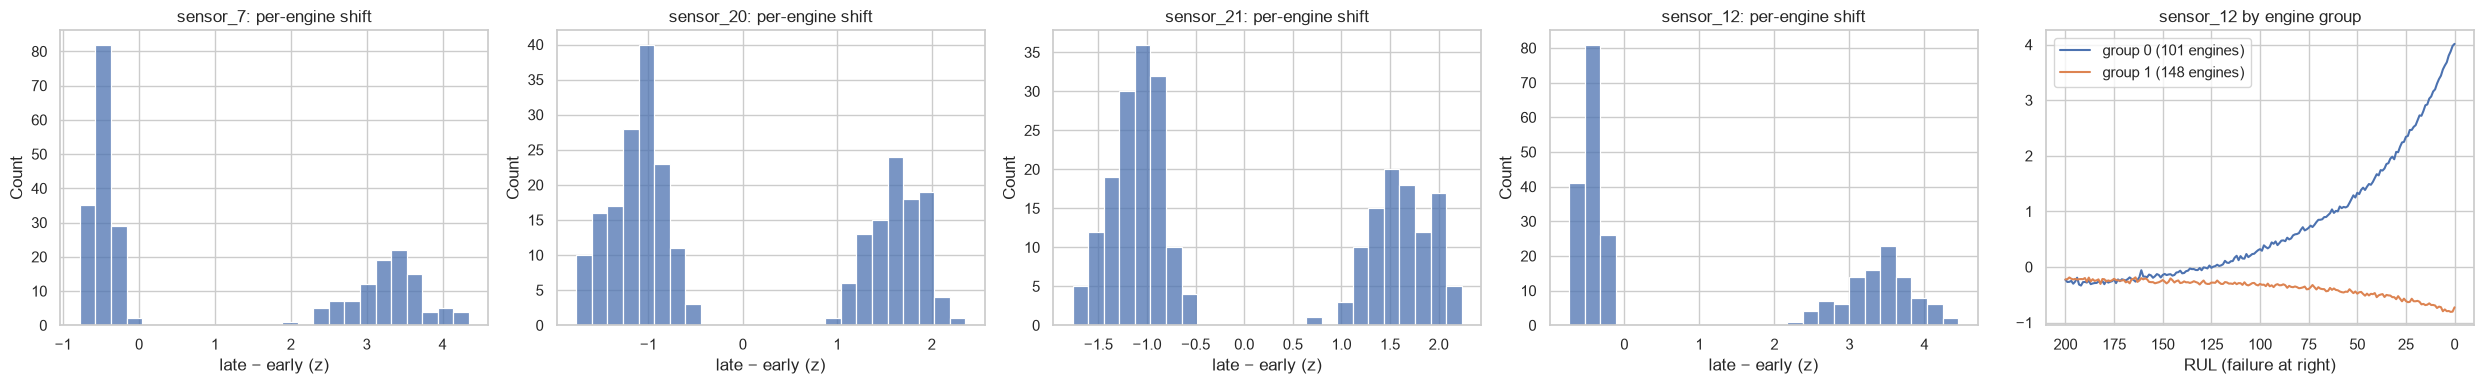

In [14]:
# Cell 13 — Per-engine shift of each sensor (late − early, in normalised units)
early_e = z[z.cycle <= 30].groupby("engine_id")[CHECK].mean()
late_e = z[z.RUL < 30].groupby("engine_id")[CHECK].mean()
eshift = late_e - early_e
share_up = (eshift > 0).mean().rename("share_of_engines_rising")
spread = eshift.std().rename("spread_between_engines")
fm = pd.concat([share_up, eshift.mean().rename("mean_shift"), spread], axis=1).sort_values("share_of_engines_rising")
display(fm.round(2))
SPLIT = fm.index[(fm.share_of_engines_rising > 0.2) & (fm.share_of_engines_rising < 0.8) & (fm.spread_between_engines > 1)].tolist()
print("Sensors that rise in some engines and fall in others:", SPLIT)

from sklearn.cluster import KMeans
km2 = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(eshift[SPLIT] if SPLIT else eshift)
groups = pd.Series(km2.labels_, index=eshift.index, name="group")
print("Engines per group:", groups.value_counts().sort_index().to_dict())
print("Mean shift per group:"); display(eshift[SPLIT].groupby(groups).mean().round(2) if SPLIT else None)

show = SPLIT[:4] if SPLIT else CHECK[:4]
fig, axes = plt.subplots(1, len(show) + 1, figsize=(5 * (len(show) + 1), 4))
for ax, col in zip(axes, show):
    sns.histplot(eshift[col], bins=25, ax=ax); ax.set(title=f"{col}: per-engine shift", xlabel="late − early (z)")
zz = z.merge(groups, left_on="engine_id", right_index=True)
col = show[-1]
for gname, sub in zz[zz.RUL <= 200].groupby("group"):
    m_ = sub.groupby("RUL")[col].mean()
    axes[-1].plot(m_.index, m_.values, label=f"group {gname} ({(groups == gname).sum()} engines)")
axes[-1].invert_xaxis(); axes[-1].legend(); axes[-1].set(title=f"{col} by engine group", xlabel="RUL (failure at right)")
fig.tight_layout(); save_fig(fig, "08_fault_modes"); plt.show()

**Implications for modelling:**
- **Linear Regression** gives each feature one fixed weight, so it can't represent "up for fault A, down for fault B". It is expected to struggle more here than on FD001.
- **Tree models** can split on the direction of the trend (rolling **slope** features), and the **LSTM** sees the direction of the recent history. Both can handle the two modes without being told which one an engine has.
- Sensors with a near-zero overall correlation but a large per-engine spread should **not** be dropped just because their correlation is low.

## 2.12 — RUL distribution

{'count': 61249.0, 'mean': 133.3, 'std': 89.8, 'min': 0.0, '25%': 61.0, '50%': 122.0, '75%': 190.0, 'max': 542.0}
Share of rows with RUL > 100: 58.9%
Share of rows with RUL > 125: 48.8%
Share of rows with RUL > 150: 38.8%


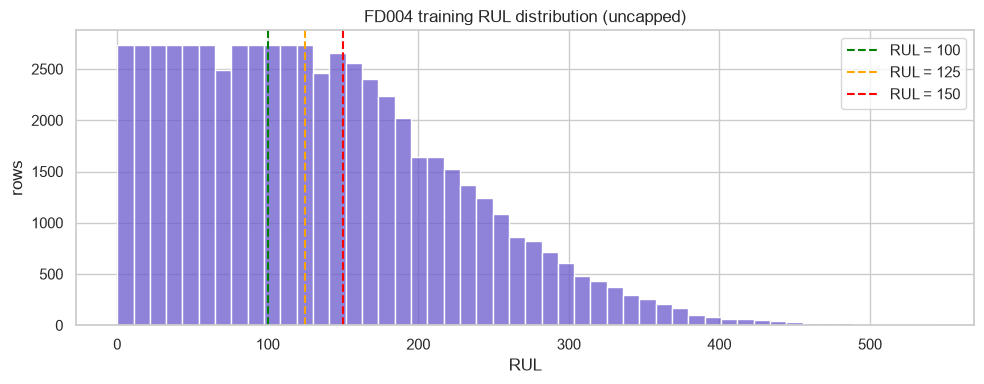

In [15]:
# Cell 14 — Training RUL (uncapped)
print(eda.RUL.describe().round(1).to_dict())
for t in (100, 125, 150):
    print(f"Share of rows with RUL > {t}: {(eda.RUL > t).mean():.1%}")
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(eda.RUL, bins=50, ax=ax, color="slateblue")
for t, c in zip((100, 125, 150), ("green", "orange", "red")):
    ax.axvline(t, color=c, ls="--", label=f"RUL = {t}")
ax.set(title=f"{FD} training RUL distribution (uncapped)", xlabel="RUL", ylabel="rows"); ax.legend()
fig.tight_layout(); save_fig(fig, "09_rul_distribution"); plt.show()

## Cell 15 — Save findings

In [16]:
# Cell 15 — Machine-readable findings
findings = {
    "dataset": FD, "n_train_engines": int(train.engine_id.nunique()), "n_test_engines": int(test.engine_id.nunique()),
    "train_lifetime_min": int(train_life.min()), "train_lifetime_max": int(train_life.max()),
    "train_lifetime_median": float(train_life.median()), "test_observed_min": int(test_obs.min()),
    "test_engines_below_21": int((test_obs < 21).sum()), "test_engines_below_30": int((test_obs < 30).sum()),
    "n_regimes": int(N_REGIMES), "regime_change_rate": round(float(switch_rate), 3),
    "constant": CONSTANT, "quantised": QUANT, "variable": VARIABLE,
    "corr_normalised": corr["normalised"].round(3).to_dict(),
    "split_direction_sensors": SPLIT, "fault_groups": groups.value_counts().sort_index().tolist(),
    "share_rows_rul_gt_125": round(float((eda.RUL > 125).mean()), 3),
}
(TAB_DIR / "eda_findings.json").write_text(json.dumps(findings, indent=2, default=float))
print(json.dumps({k: v for k, v in findings.items() if k != "corr_normalised"}, indent=1, default=float))

{
 "dataset": "FD004",
 "n_train_engines": 249,
 "n_test_engines": 248,
 "train_lifetime_min": 128,
 "train_lifetime_max": 543,
 "train_lifetime_median": 234.0,
 "test_observed_min": 19,
 "test_engines_below_21": 4,
 "test_engines_below_30": 11,
 "n_regimes": 6,
 "regime_change_rate": 0.821,
 "constant": [
  "sensor_1",
  "sensor_5",
  "sensor_18",
  "sensor_19"
 ],
 "quantised": [
  "sensor_16"
 ],
 "variable": [
  "sensor_2",
  "sensor_3",
  "sensor_4",
  "sensor_6",
  "sensor_7",
  "sensor_8",
  "sensor_9",
  "sensor_10",
  "sensor_11",
  "sensor_12",
  "sensor_13",
  "sensor_14",
  "sensor_15",
  "sensor_17",
  "sensor_20",
  "sensor_21"
 ],
 "split_direction_sensors": [
  "sensor_7",
  "sensor_20",
  "sensor_21",
  "sensor_12",
  "sensor_10",
  "sensor_15",
  "sensor_14"
 ],
 "fault_groups": [
  101,
  148
 ],
 "share_rows_rul_gt_125": 0.488
}


---
## Key findings (actual values from a full local run)
- **Lifetimes 128–543 cycles** (median 234), longer and more spread out than FD001/FD002.
- **Shortest test history: 19 cycles** (11 test engines below 30) → the LSTM window must be ≤ 19.
- **6 operating regimes**, re-drawn on 82% of cycles → per-regime normalisation needed (as FD002).
- **Constant sensors:** sensor_1, sensor_5, sensor_18, sensor_19. **Quantised:** sensor_16.
- **Strongest correlations with RUL:** `sensor_11` -0.69, `sensor_4` -0.65, `sensor_17` -0.61, `sensor_3` -0.58.
- **Two fault modes confirmed:** sensor_7, sensor_20, sensor_21, sensor_12, sensor_10, sensor_15, sensor_14 rise in some engines and fall in others. K-Means splits the engines into groups of 101 and 148. That's why `sensor_15`, `sensor_21`, `sensor_20` show a correlation near 0 despite carrying signal.
- **49% of training rows have RUL > 125**, so the cap experiment is repeated in Phase 3.

## Proposals for Phase 3 (`12_Preprocessing_FD004`)
| Topic | Proposed action |
|---|---|
| Scaling | Per-regime StandardScaler (as FD002), with Experiment A re-checking global vs regime |
| Sensors | Drop constant sensors; test "core 14 sensors" vs the rule-based set (which keeps the extra quantised sensors) on validation |
| Low-correlation sensors | Keep them: fault-mode sensors matter even with a correlation near 0 |
| RUL cap | Re-run the cap experiment (none / 100 / 125 / 150) |
| LSTM window | ≤ 19 cycles (shortest test engine) |